# Task 3: Classical Machine Learning Classification & Hyperparameter Tuning
**Course:** AI in Cyber Security Lab (`ENSP355`) — Unit 1 Capstone  
**Student:** Yatharth Chopra (`2301420022`) | **Program:** B.Tech CSE (Data Science), Sem 7  
**University:** K.R. Mangalam University | **Faculty:** Monika Khatkar

---

### Models Evaluated
1. **Logistic Regression** (linear baseline)
2. **Decision Tree** (`max_depth=6`, interpretable rules)
3. **Random Forest** (`n_estimators=200, max_depth=12`, bagging ensemble)
4. **Gradient Boosting** (`HistGradientBoostingClassifier`, sequential boosting)

Plus **3-Fold Stratified `GridSearchCV` Hyperparameter Tuning** on Random Forest and model persistence (`models/best_rf_pipeline.joblib`).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from common import FEATURES, OUT_DIR, RANDOM_STATE, load_data
from preprocessing import build_preprocessor, split_data
from evaluation import fit_and_score

df = load_data()
X_train, X_test, y_train, y_test = split_data(df)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows | Threat Share: {y_test.mean():.3f}")

Train: 9,926 rows | Test: 2,482 rows | Threat Share: 0.460


## 1) Train Classical Models & Plot Confusion Matrices

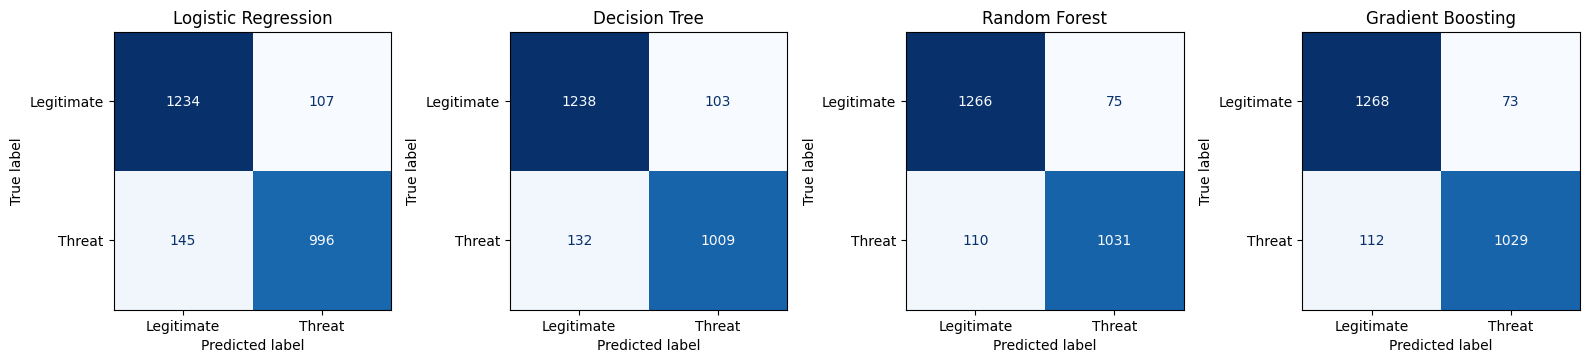

In [2]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(max_iter=200, max_depth=8, learning_rate=0.08, random_state=RANDOM_STATE),
}

results, fitted = [], {}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, clf) in zip(axes, models.items()):
    pipe = Pipeline([("prep", build_preprocessor()), ("clf", clf)])
    res, pred = fit_and_score(pipe, X_train, X_test, y_train, y_test)
    results.append({"model": name, **res})
    fitted[name] = pipe
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Legitimate", "Threat"], cmap="Blues", ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 2) Comprehensive Metrics Table (Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, TN/FP/FN/TP)

In [3]:
res_df = pd.DataFrame(results).round(4)
display(res_df[["model", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "tn", "fp", "fn", "tp", "acc_unseen_profiles"]])

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp,acc_unseen_profiles
0,Logistic Regression,0.8985,0.9030,0.8729,0.8877,0.9643,0.9596,1234,107,145,996,0.7213
1,Decision Tree,0.9053,0.9074,0.8843,0.8957,0.9705,0.9638,1238,103,132,1009,0.8361
2,Random Forest,0.9255,0.9322,0.9036,0.9177,0.9797,0.9786,1266,75,110,1031,0.8525
3,Gradient Boosting,0.9255,0.9338,0.9018,0.9175,0.9788,0.9774,1268,73,112,1029,0.8443


## 3) Feature Importance & Random Forest GridSearchCV Tuning

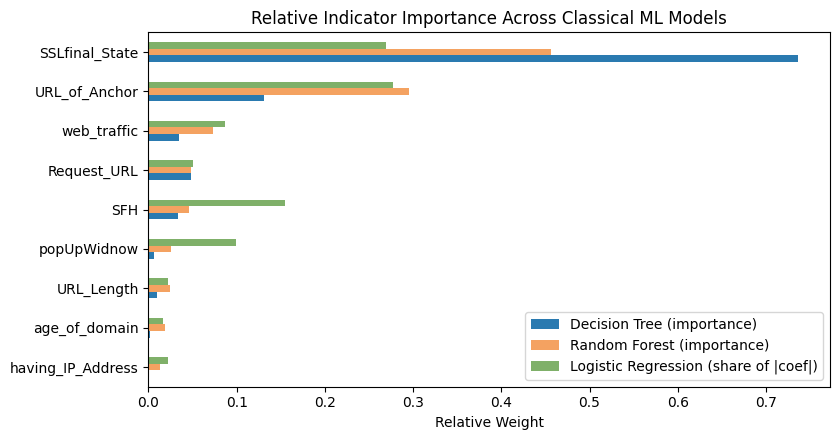

Random Forest 3-Fold Stratified GridSearchCV Results:


,param_clf__n_estimators,param_clf__max_depth,mean_test_score,std_test_score,rank_test_score
0,100,12.0,0.9135,0.0068,1
1,200,12.0,0.9131,0.0067,2
2,100,NaN,0.9129,0.0053,3
3,200,NaN,0.9124,0.0068,4
4,200,8.0,0.9097,0.0079,5
5,100,8.0,0.9093,0.0073,6


In [4]:
imp = pd.read_csv(OUT_DIR / "feature_importance.csv", index_col=0)
fig, ax = plt.subplots(figsize=(8.5, 4.5))
imp.plot.barh(ax=ax, color=["#2a7ab0", "#f4a261", "#7fb069"])
ax.set_title("Relative Indicator Importance Across Classical ML Models")
ax.set_xlabel("Relative Weight")
plt.tight_layout()
plt.show()

print("Random Forest 3-Fold Stratified GridSearchCV Results:")
display(pd.read_csv(OUT_DIR / "rf_tuning_results.csv"))